<a href="https://www.kaggle.com/code/shokos64/0-11936-house-prices-lgbm-cat-japanese?scriptVersionId=356986827" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

Hi! I am a Kaggle beginner and not fluent in English, so this notebook is written in Japanese.

Please use your browser's translation (or DeepL/ChatGPT) to read it!

Hope it helps!

# これまでの進捗（簡易版）

| 内容 | LB |
| ---- | ---- |
| LightGBM によるパイプライン構築 | 0.13458 |
| 目標変数 SalePrice の対数変換 | 0.12960 |
| EDA, 外れ値の削除 | 0.12746 |
| ハイパーパラメータの調整 | 0.12399 |
| アンサンブル | 0.11936 |

LightGBM 単体で、0.12399 までスコアを伸ばし、最後の仕上げとして CatBoost とアンサンブルして、最終スコア 0.11936を達成。

# 準備

## ライブラリのインポート

In [1]:
import pandas as pd
import numpy as np

import lightgbm as lgb
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error

import matplotlib.pyplot as plt
import seaborn as sns

## CSV の読み込み

In [2]:
import kagglehub

path = kagglehub.competition_download("house-prices-advanced-regression-techniques")

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/house-prices-advanced-regression-techniques


In [3]:
train = pd.read_csv("../input/competitions/house-prices-advanced-regression-techniques/train.csv")
test = pd.read_csv("../input/competitions/house-prices-advanced-regression-techniques/test.csv")
sample_submission = pd.read_csv("../input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv")

# データの確認

## 各データのプレビュー・件数確認

今回の目的変数は `SalePrice`。　`test` の物件の販売価格をそれぞれ予測しよう、がテーマである。

件数の把握は様々な局面で重要、ここで確認しておく。

In [4]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [6]:
sample_submission.head()

,Id,SalePrice
0,1461,169277.052498
1,1462,187758.393989
2,1463,183583.683570
3,1464,179317.477511
4,1465,150730.079977


In [7]:
print(f"train の件数 = {len(train)}")
print(f"test の件数 = {len(test)}")
print(f"sample_submission の件数 = {len(sample_submission)}")

train の件数 = 1460
test の件数 = 1459
sample_submission の件数 = 1459


## 各列のデータ型確認

学習データとなる `train` の各列の情報を確認。

Non-Null Count は、欠損値となっていないデータの数を表す。　先程、`train` のデータ数（1460件）は確認したので、ここで欠損値の割合をざっくりイメージする。

Dtype は各列のデータ型。　LightGBM は数値型やカテゴリ型のデータ型は扱えるが、object型（主に文字列）はそのままじゃ扱えない点に注意。

In [8]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

# 特徴量の抽出

## 既存の列の処理

In [9]:
# 不必要な列の削除（欠損値が 50% 以上の列、欠損値 50% ライン = 730）
drop_cols = ['Alley', 'PoolQC', 'Fence', 'MiscFeature']
train = train.drop(columns=drop_cols)
test = test.drop(columns=drop_cols)

# 文字列型の特徴量をカテゴリ型に変換
cat_cols = train.select_dtypes(include=['object']).columns

# .fillna("Missing") は CatBoost 用の処理（ CatBoost は後ほどアンサンブルで使う）
for c in cat_cols:
    train[c] = train[c].fillna("Missing").astype('category')
    test[c] = test[c].fillna("Missing").astype('category')

## EDA

### 面積を整理した特徴量 ( `TotalHouseSF` , `TotalOutdoorSF` )

In [10]:
# 屋内の総面積　地上部分の居住面積 + 地下室の総面積
# 1階・2階は GrLivArea に含まれるため除外
train['TotalHouseSF'] = train['GrLivArea'] + train['TotalBsmtSF']
test['TotalHouseSF'] = test['GrLivArea'] + test['TotalBsmtSF']

# 屋外・付属設備　ガレージ + ウッドデッキ + ポーチ
# 敷地 LotArea は設備とは言えないため除外
train['TotalOutdoorSF'] = train['GarageArea'] + train['WoodDeckSF'] + train['OpenPorchSF']
test['TotalOutdoorSF'] = test['GarageArea'] + test['WoodDeckSF'] + test['OpenPorchSF']

### 品質を表す特徴量 ( `Qual2_Cond_Mult` )

既存列で特に重要と思われるのは、この2つ。

describe を見てみると、どちらも 10 点満点のスコアで表されているのではと、なんとなく推測できる（min, max あたりがわかりやすい）。

- `OverallCond` : 全体的な現在の保存状態
- `OverallQual` : 全体的な建築素材や仕上げの品質・グレード

一般的には、`OverallQual` の方が販売価格により強く影響すると考え、こちらに重みを付けて交互作用特徴量を作成する。

In [11]:
print("--- OverallCond（全体的な現在の保存状態） の describe ---")
display(train['OverallCond'].describe())

print("\n--- OverallQual（全体的な建築素材や仕上げの品質・グレード） の describe ---")
display(train['OverallQual'].describe())

--- OverallCond（全体的な現在の保存状態） の describe ---


count    1460.000000
mean        5.575342
std         1.112799
min         1.000000
25%         5.000000
50%         5.000000
75%         6.000000
max         9.000000
Name: OverallCond, dtype: float64


--- OverallQual（全体的な建築素材や仕上げの品質・グレード） の describe ---


count    1460.000000
mean        6.099315
std         1.382997
min         1.000000
25%         5.000000
50%         6.000000
75%         7.000000
max        10.000000
Name: OverallQual, dtype: float64

In [12]:
# OverallCond^2 * OverallQual
train['Qual2_Cond_Mult'] = (train['OverallQual']**2) * train['OverallCond']
test['Qual2_Cond_Mult'] = (test['OverallQual']**2) * test['OverallCond']

### 広さ × 品質の複合特徴量 ( `HouseSF_Qual_log` )

これも、販売価格を左右するには重要な指標だと推測する。　広くて高品質な家ほど価格が跳ね上がる、という相乗効果を表現する。

ただし、掛け算によって数値が極端に大きくなり、分布が右に長く伸びてしまう（歪む）ため、`np.log1p` で対数変換を行ってデータのスケールを整える。

こうすることで、モデル（決定木）が極端な大値に引っ張られるのを防ぎ、扱いやすいなめらかな分布に変換する。

In [13]:
train['HouseSF_Qual_log'] = np.log1p(train['TotalHouseSF'] * train['OverallQual'])
test['HouseSF_Qual_log'] = np.log1p(test['TotalHouseSF'] * test['OverallQual'])

### 築年数 ( `Age` )

In [14]:
train["Age"] = train["YrSold"] - train["YearBuilt"]
test["Age"] = test["YrSold"] - test["YearBuilt"]

### 試したけど不採用にしたアプローチ（代表的なもの）

これらはスコアが伸びなかった。

- `MoSold` から販売月の周期性を抽出する。　sin / cos 変換や、季節カテゴリの作成など。
- `MasVnrArea` (石積み化粧壁の面積) を高級住宅のフラグにする。
- `Neighborhood` でエリアごとの販売価格の中央値を算出・活用。
- `LotFrontage` 等で、日常生活での駐車等のしやすさ、アメリカの車社会という背景を考慮。
- 建ぺい率を算出してみる。

# 外れ値の削除

散布図の右下 2 件の外れ値を削除する。

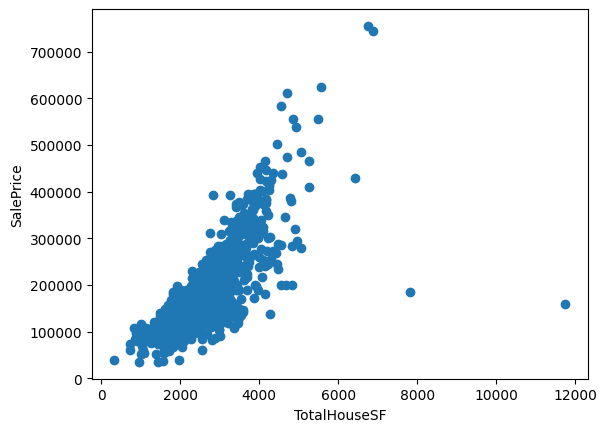

In [15]:
plt.scatter(train['TotalHouseSF'], train['SalePrice'])
plt.xlabel("TotalHouseSF")
plt.ylabel("SalePrice")
plt.show()

In [16]:
# 外れ値のインデックスを特定して除外
outliers = train[(train['TotalHouseSF'] > 7000) & (train['SalePrice'] < 250000)].index

# 外れ値を除外した train データを作成
train = train.drop(outliers).reset_index(drop=True)

print(f"検出された外れ値の数: {len(outliers)}")

検出された外れ値の数: 2


# LightGBM 単体

## 関数の定義

In [17]:
def plot_feature_importance(importance_df, top_n=20):
    """
    特徴量重要度のデータフレームを受け取り、上位 top_n 件を横棒グラフで描画する関数
    """
    plt.figure(figsize=(10, 8))
    sns.barplot(
        x='importance',
        y='feature',
        data=importance_df.head(top_n),
        palette='viridis',
        hue='feature',
        legend=False
    )
    plt.title(f'LightGBM Feature Importance (Top {top_n})')
    plt.xlabel('Importance')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

In [18]:
def train_lgb(train_df, test_df, feature_cols, target_col="SalePrice"):
    """
    指定された特徴量で LightGBM の交差検証学習を行い、
    OOF予測値、テスト予測値、学習済みモデル群を返す関数
    """
    # 特徴量と目的変数の分離（元の train_df の列は書き換えない）
    X_train = train_df[feature_cols]
    X_test = test_df[feature_cols]
    y_train = np.log1p(train_df[target_col])

    cv = KFold(n_splits=5, shuffle=True, random_state=0)
    callbacks = [lgb.early_stopping(stopping_rounds=100, verbose=False)]

    models = []
    y_preds = []
    oof_train = np.zeros(len(X_train))

    for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train, y_train)):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_va, y_va = X_train.iloc[valid_idx], y_train.iloc[valid_idx]

        # ハイパーパラメータ
        model = lgb.LGBMRegressor(
            learning_rate=0.02,
            max_depth=3,
            num_leaves=8,
            n_estimators=3000,
            random_state=0, 
            verbose=-1
        )
        
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            callbacks=callbacks,
        )

        oof_train[valid_idx] = model.predict(X_va)
        y_preds.append(model.predict(X_test))
        models.append(model)

    return oof_train, y_preds, models

CV RMSLE (LB指標) = 0.11975
CV RMSE (ドル単位) = $ 23570.92


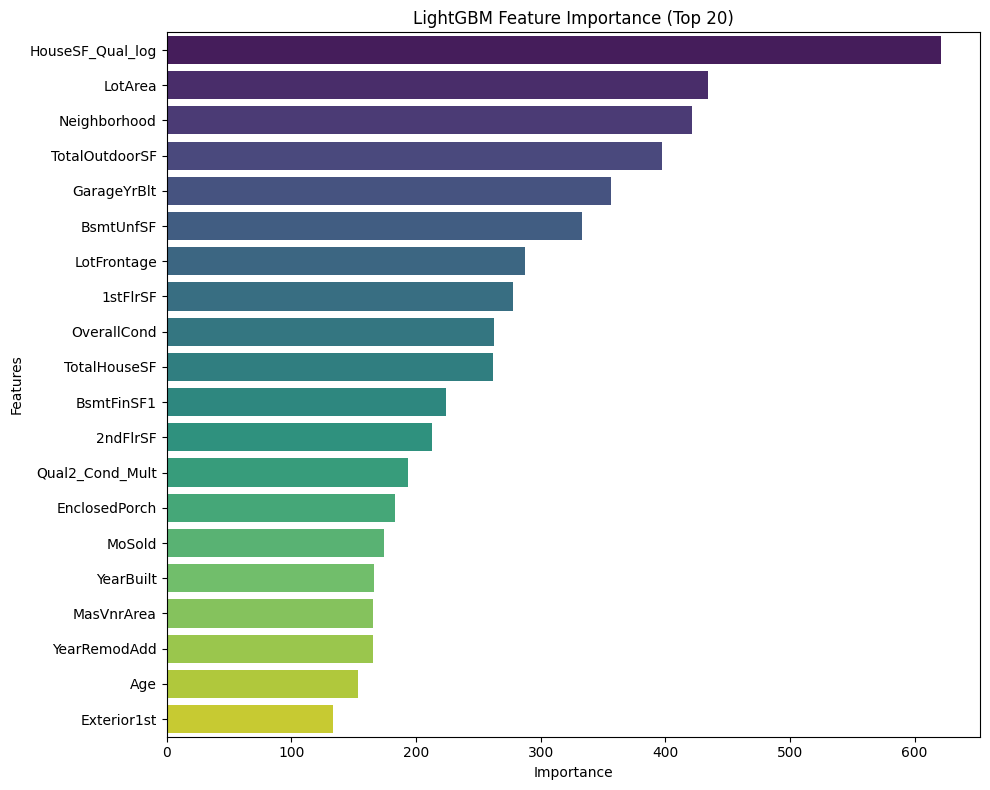

In [19]:
# 不要な列の除外
features = [
    col for col in train.columns if col not in [
        "Id",
        "SalePrice",
        "GrLivArea",
        "TotalBsmtSF",
        "GarageArea",
        "WoodDeckSF",
        "OpenPorchSF",
    ]
]

# 学習の実行
oof_train, y_preds, models = train_lgb(train, test, features)


# --------------------------------------------------
# 1. RMSLE (Kaggle Leaderboard の評価指標と同等)
# --------------------------------------------------
# train['SalePrice'] が対数(20未満)ならそのまま使い、生データなら log1p する
y_true_log = (
    train["SalePrice"]
    if train["SalePrice"].max() < 20
    else np.log1p(train["SalePrice"])
)

# 対数スケール同士（oof_train vs y_true_log）で計算した RMSE は RMSLE になる
cv_rmsle = root_mean_squared_error(y_true_log, oof_train)


# --------------------------------------------------
# 2. RMSE (実際のドル単位の誤差)
# --------------------------------------------------
# 両方を expm1 で元のドル単位に戻して比較
oof_train_exp = np.expm1(oof_train)
y_true_exp = np.expm1(y_true_log)

cv_rmse = root_mean_squared_error(y_true_exp, oof_train_exp)


# --------------------------------------------------
# スコアの出力
# --------------------------------------------------
print(f"CV RMSLE (LB指標) = {round(cv_rmsle, 5)}")
print(f"CV RMSE (ドル単位) = $ {round(cv_rmse, 2)}")


# --------------------------------------------------
# 特徴量重要度の集計と可視化
# --------------------------------------------------
importance_df = (
    pd.DataFrame(
        {
            "feature": features,
            "importance": np.mean(
                [m.feature_importances_ for m in models], axis=0
            ),
        }
    )
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

# 上位 20 件の可視化
plot_feature_importance(importance_df, top_n=20)

# 上位 20 件のデータフレーム表示
# importance_df.head(20)

# アンサンブル（LightGBM, CatBoost）

グリッドサーチした結果、導き出された最適な比率

LightGBM 0.33, CatBoost 0.67

## 関数の定義

In [20]:
from catboost import CatBoostRegressor


def train_ensemble(
    train_df, test_df, feature_cols, target_col="SalePrice"
):
    X_train = train_df[feature_cols]
    X_test = test_df[feature_cols]
    y_train = np.log1p(train_df[target_col])

    cv = KFold(n_splits=5, shuffle=True, random_state=0)

    lgb_oof = np.zeros(len(X_train))
    cb_oof = np.zeros(len(X_train))

    lgb_preds = []
    cb_preds = []

    # category 型の列名を特定しておく（CatBoost用）
    cat_features = X_train.select_dtypes(include=["category"]).columns.tolist()

    for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train, y_train)):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_va, y_va = X_train.iloc[valid_idx], y_train.iloc[valid_idx]

        # --- 1. LightGBM ---
        model_lgb = lgb.LGBMRegressor(
            learning_rate=0.05,
            max_depth=3,
            num_leaves=8,
            n_estimators=1000,
            random_state=0,
            verbose=-1,
        )
        model_lgb.fit(
            X_tr,
            y_tr,
            eval_set=[(X_va, y_va)],
            callbacks=[lgb.early_stopping(100, verbose=False)],
        )
        lgb_oof[valid_idx] = model_lgb.predict(X_va)
        lgb_preds.append(model_lgb.predict(X_test))

        # --- 2. CatBoost ---
        model_cb = CatBoostRegressor(
            iterations=1000,
            learning_rate=0.05,
            depth=4,
            random_seed=0,
            verbose=0,
            cat_features=cat_features,  # カテゴリ列をそのまま渡すだけ
        )
        model_cb.fit(
            X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=100
        )
        cb_oof[valid_idx] = model_cb.predict(X_va)
        cb_preds.append(model_cb.predict(X_test))

    return lgb_oof, cb_oof, lgb_preds, cb_preds

## グリッドサーチ

In [21]:
# # 学習の実行
# lgb_oof, cb_oof, lgb_preds, cb_preds = train_ensemble(train, test, features)

# # 1. それぞれ単体の OOF スコアを確認
# y_true_log = np.log1p(train["SalePrice"])
# print(f"LightGBM 単体 RMSLE : {root_mean_squared_error(y_true_log, lgb_oof):.5f}")
# print(f"CatBoost 単体 RMSLE : {root_mean_squared_error(y_true_log, cb_oof):.5f}")
# print("-" * 40)

# # 2. 5:5 ブレンドの OOF スコアを確認
# default_ensemble_oof = 0.5 * lgb_oof + 0.5 * cb_oof
# default_blend_rmsle = root_mean_squared_error(y_true_log, default_ensemble_oof)
# print(f"従来 (5:5) CV RMSLE : {default_blend_rmsle:.5f}")

# # 3. 最適な重み（比率）のグリッドサーチ
# best_score = float('inf')
# best_w_lgb = 0.5

# # LightGBM の重みを 0.00 から 1.00 まで 0.01 刻みで探索
# for w in np.linspace(0, 1, 101):
#     blend_oof = w * lgb_oof + (1 - w) * cb_oof
#     score = root_mean_squared_error(y_true_log, blend_oof)
#     if score < best_score:
#         best_score = score
#         best_w_lgb = w

# best_w_cb = 1.0 - best_w_lgb

# print("-" * 40)
# print(f"★ 最適重み -> LightGBM: {best_w_lgb:.2f} / CatBoost: {best_w_cb:.2f}")
# print(f"★ 最適化後の CV RMSLE : {best_score:.5f}")

## 学習

In [22]:
# 学習の実行
lgb_oof, cb_oof, lgb_preds, cb_preds = train_ensemble(train, test, features)

# 1. それぞれ単体の OOF スコアを確認
y_true_log = np.log1p(train["SalePrice"])
print(f"LightGBM 単体 RMSLE : {root_mean_squared_error(y_true_log, lgb_oof):.5f}")
print(f"CatBoost 単体 RMSLE : {root_mean_squared_error(y_true_log, cb_oof):.5f}")

# 2. ブレンドした OOF スコアを確認
ensemble_oof = 0.33 * lgb_oof + 0.67 * cb_oof
blend_rmsle = root_mean_squared_error(y_true_log, ensemble_oof)

# --------------------------------------------------
# 3. RMSE (実際のドル単位の誤差) の計算
# --------------------------------------------------
ensemble_oof_exp = np.expm1(ensemble_oof)
y_true_exp = np.expm1(y_true_log)
blend_rmse = root_mean_squared_error(y_true_exp, ensemble_oof_exp)

# --------------------------------------------------
# スコアの出力
# --------------------------------------------------
print("-" * 40)
print(f"★ アンサンブル CV RMSLE (LB指標) : {blend_rmsle:.5f}")
print(f"★ アンサンブル CV RMSE (ドル単位) : $ {round(blend_rmse, 2):,}")

LightGBM 単体 RMSLE : 0.11968
CatBoost 単体 RMSLE : 0.11552
----------------------------------------
★ アンサンブル CV RMSLE (LB指標) : 0.11407
★ アンサンブル CV RMSE (ドル単位) : $ 22,429.27


# 提出

In [23]:
# 1. LightGBM と CatBoost の fold 平均予測値をそれぞれ計算 (log スケール)
lgb_final_preds_log = np.mean(lgb_preds, axis=0)
cb_final_preds_log = np.mean(cb_preds, axis=0)

# 2. ブレンドし、np.expm1 で元のドル単位に戻す
ensemble_final_preds_log = 0.33 * lgb_final_preds_log + 0.67 * cb_final_preds_log
final_preds = np.expm1(ensemble_final_preds_log)

# 3. sample_submission をコピーして予測値を代入
sub = sample_submission.copy()
sub["SalePrice"] = final_preds

# 4. submission.csv として出力
sub.to_csv("submission.csv", index=False)

# 5. 中身と件数の確認
print(f"提出データの件数: {len(sub)}")  # 1459 件なら OK
print(f"欠損値の数: {sub.isnull().sum().sum()}")  # 0 件なら OK
sub.head()

提出データの件数: 1459
欠損値の数: 0


,Id,SalePrice
0,1461,122627.740514
1,1462,164157.422166
2,1463,180771.312708
3,1464,197371.591162
4,1465,190461.782479
